Zero-electric-field g tensor components:
gxx = 0.28628072
gyy = 0.43982912
gzz = 15.76692243


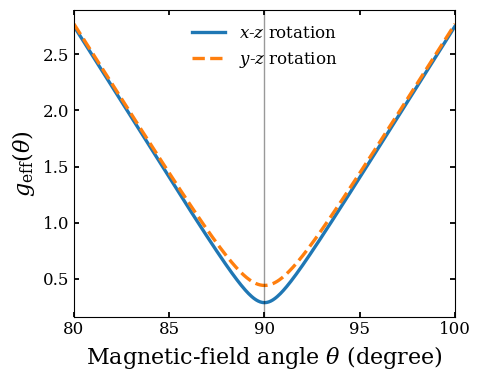

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# Plot settings
# ==================================================
plt.rcParams.update({
    "figure.figsize": [4, 4],
    "font.family": "Serif",
    "mathtext.fontset": "dejavuserif",
    "axes.linewidth": 0.8
})

# ==================================================
# Load zero-electric-field g values
# ==================================================
# These files contain electric-field sweeps.
# The first row corresponds to E = 0.
data_xx = np.loadtxt("gfactor_xx_vs_Ey_N100_L300.dat", comments="#")
data_yy = np.loadtxt("gfactor_yy_vs_Ey_N100_L300.dat", comments="#")
data_zz = np.loadtxt("gfactor_zz_vs_Ey_N100_L300.dat", comments="#")

gxx0 = abs(data_xx[0,7])
gyy0 = abs(data_yy[0,7])
gzz0 = abs(data_zz[0,7])

print("Zero-electric-field g tensor components:")
print(f"gxx = {gxx0:.8f}")
print(f"gyy = {gyy0:.8f}")
print(f"gzz = {gzz0:.8f}")

# ==================================================
# Angular sweep
# ==================================================
theta_deg = np.linspace(80, 100, 361)
theta = np.deg2rad(theta_deg)

# Rotation in x-z plane:
# theta = 0   -> B along x
# theta = 90  -> B along z
g_xz = np.sqrt((gxx0 * np.sin(theta))**2 + (gzz0 * np.cos(theta))**2)

# Rotation in y-z plane:
# theta = 0   -> B along y
# theta = 90  -> B along z
g_yz = np.sqrt((gyy0 * np.sin(theta))**2 + (gzz0 * np.cos(theta))**2)

# ==================================================
# Plot
# ==================================================
plt.figure(figsize=(5, 4))

plt.plot(
    theta_deg,
    g_xz,
    "-",
    label=r"$x$-$z$ rotation"
)

plt.plot(
    theta_deg,
    g_yz,
    "--",
    label=r"$y$-$z$ rotation"
)
plt.xlim(theta_deg[0], theta_deg[-1])
plt.axvline(90, color="black", linewidth=1.0, alpha=0.4)

plt.xlabel(r"Magnetic-field angle $\theta$ (degree)")
plt.ylabel(r"$g_{\rm eff}(\theta)$")
# plt.title(r"Angular dependence of $g_{\rm eff}$ at $E=0$")

plt.legend(frameon=False)
# plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig("angular_geff_zeroE_N100_L300.pdf", dpi=300, bbox_inches="tight")
plt.savefig("angular_geff_zeroE_N100_L300.png", dpi=300, bbox_inches="tight")

plt.show()

E = 0:
gxx = 0.28628072
gyy = 0.43982912
gzz = 15.76692243

E = 0.060000 V/um:
gxx = 0.28698163
gyy = 0.46920091
gzz = 15.60585791


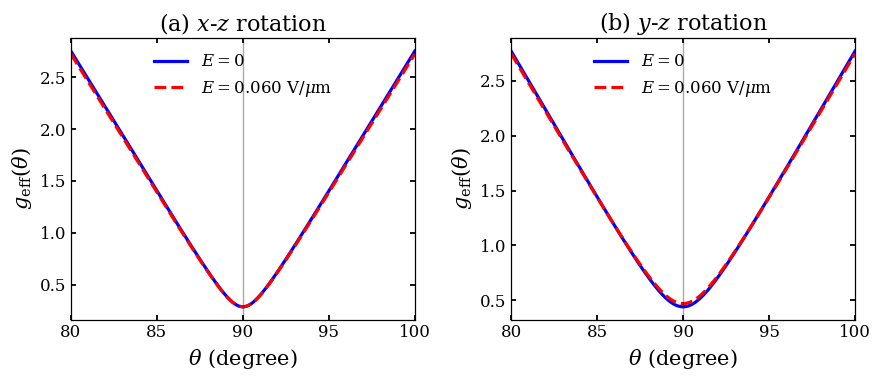

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# Plot settings
# ==================================================
plt.rcParams.update({
    "figure.figsize": [8, 4],
    "font.family": "Serif",
    "mathtext.fontset": "dejavuserif",
    "axes.linewidth": 0.9,
    "font.size": 13,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "lines.linewidth": 2.3,
})

# ==================================================
# Load g-factor data
# ==================================================
data_xx = np.loadtxt("gfactor_xx_vs_Ey_N100_L300.dat", comments="#")
data_yy = np.loadtxt("gfactor_yy_vs_Ey_N100_L300.dat", comments="#")
data_zz = np.loadtxt("gfactor_zz_vs_Ey_N100_L300.dat", comments="#")

# --------------------------------------------------
# Row 0: E = 0
# Row 1: finite electric field
# --------------------------------------------------
gxx_E0 = abs(data_xx[0, 7])
gyy_E0 = abs(data_yy[0, 7])
gzz_E0 = abs(data_zz[0, 7])

gxx_E1 = abs(data_xx[1, 7])
gyy_E1 = abs(data_yy[1, 7])
gzz_E1 = abs(data_zz[1, 7])

E1_val = data_xx[1, 2]   # electric field in V/um

print("E = 0:")
print(f"gxx = {gxx_E0:.8f}")
print(f"gyy = {gyy_E0:.8f}")
print(f"gzz = {gzz_E0:.8f}")

print(f"\nE = {E1_val:.6f} V/um:")
print(f"gxx = {gxx_E1:.8f}")
print(f"gyy = {gyy_E1:.8f}")
print(f"gzz = {gzz_E1:.8f}")

# ==================================================
# Angular sweep: zoom near in-plane direction
# theta = 0 degree  -> B || z
# theta = 90 degree -> B || x or y
# ==================================================
theta_deg = np.linspace(80, 100, 501)
theta = np.deg2rad(theta_deg)

# x-z rotation
g_xz_E0 = np.sqrt((gxx_E0 * np.sin(theta))**2 + (gzz_E0 * np.cos(theta))**2)
g_xz_E1 = np.sqrt((gxx_E1 * np.sin(theta))**2 + (gzz_E1 * np.cos(theta))**2)

# y-z rotation
g_yz_E0 = np.sqrt((gyy_E0 * np.sin(theta))**2 + (gzz_E0 * np.cos(theta))**2)
g_yz_E1 = np.sqrt((gyy_E1 * np.sin(theta))**2 + (gzz_E1 * np.cos(theta))**2)

# ==================================================
# Colors
# ==================================================
color_E0 = "blue"
color_E1 = "red"

# ==================================================
# Plot: two panels
# ==================================================
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True)

# --------------------------------------------------
# Panel (a): x-z rotation
# --------------------------------------------------
ax = axes[0]

ax.plot(
    theta_deg,
    g_xz_E0,
    "-",
    color=color_E0,
    label=r"$E=0$"
)

ax.plot(
    theta_deg,
    g_xz_E1,
    "--",
    color=color_E1,
    label=rf"$E={E1_val:.3f}$ V/$\mu$m"
)

ax.axvline(90, color="black", linewidth=1.0, alpha=0.35)

ax.set_xlim(theta_deg[0], theta_deg[-1])
ax.set_xlabel(r"$\theta$ (degree)")
ax.set_ylabel(r"$g_{\rm eff}(\theta)$")
ax.set_title(r"(a) $x$-$z$ rotation")
ax.legend(frameon=False)

ax.tick_params(direction="in", top=True, right=True)

# --------------------------------------------------
# Panel (b): y-z rotation
# --------------------------------------------------
ax = axes[1]

ax.plot(
    theta_deg,
    g_yz_E0,
    "-",
    color=color_E0,
    label=r"$E=0$"
)

ax.plot(
    theta_deg,
    g_yz_E1,
    "--",
    color=color_E1,
    label=rf"$E={E1_val:.3f}$ V/$\mu$m"
)

ax.axvline(90, color="black", linewidth=1.0, alpha=0.35)

ax.set_xlim(theta_deg[0], theta_deg[-1])
ax.set_xlabel(r"$\theta$ (degree)")
ax.set_ylabel(r"$g_{\rm eff}(\theta)$")
ax.set_title(r"(b) $y$-$z$ rotation")
ax.legend(frameon=False)

ax.tick_params(direction="in", top=True, right=True)

plt.tight_layout()

plt.savefig("angular_geff_zoom_E0_Efinite_N100_L300.pdf", dpi=300, bbox_inches="tight")
plt.savefig("angular_geff_zoom_E0_Efinite_N100_L300.png", dpi=300, bbox_inches="tight")

plt.show()

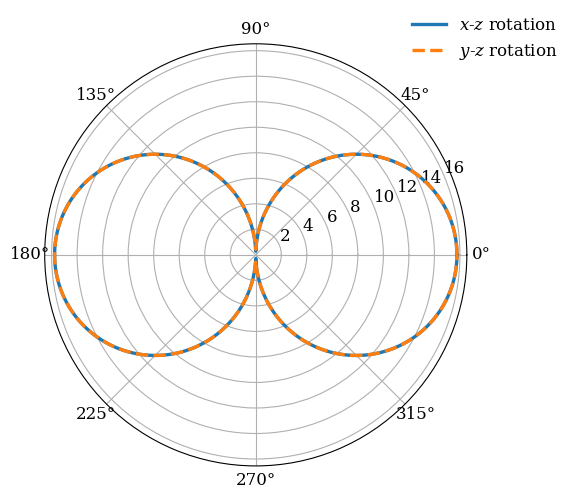

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# Load zero-electric-field g values
# ==================================================
data_xx = np.loadtxt("gfactor_xx_vs_Ey_N100_L300.dat", comments="#")
data_yy = np.loadtxt("gfactor_yy_vs_Ey_N100_L300.dat", comments="#")
data_zz = np.loadtxt("gfactor_zz_vs_Ey_N100_L300.dat", comments="#")

gxx0 = abs(data_xx[0,7])
gyy0 = abs(data_yy[0,7])
gzz0 = abs(data_zz[0,7])

theta = np.linspace(0, 2*np.pi, 721)

g_xz = np.sqrt((gxx0 * np.sin(theta))**2 + (gzz0 * np.cos(theta))**2)
g_yz = np.sqrt((gyy0 * np.sin(theta))**2 + (gzz0 * np.cos(theta))**2)

# ==================================================
# Polar plot
# ==================================================
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection="polar")

ax.plot(theta, g_xz, label=r"$x$-$z$ rotation")
ax.plot(theta, g_yz, "--", label=r"$y$-$z$ rotation")

# ax.set_title(r"Angular $g_{\rm eff}$ anisotropy at $E=0$", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.10), frameon=False)

plt.tight_layout()

plt.savefig("angular_geff_zeroE_polar_N100_L300.pdf", dpi=300, bbox_inches="tight")
plt.savefig("angular_geff_zeroE_polar_N100_L300.png", dpi=300, bbox_inches="tight")

plt.show()

E = 0:
gxx = 0.28628072, gyy = 0.43982912, gzz = 15.76692243

E = 0.060000 V/um:
gxx = 0.28698163, gyy = 0.46920091, gzz = 15.60585791


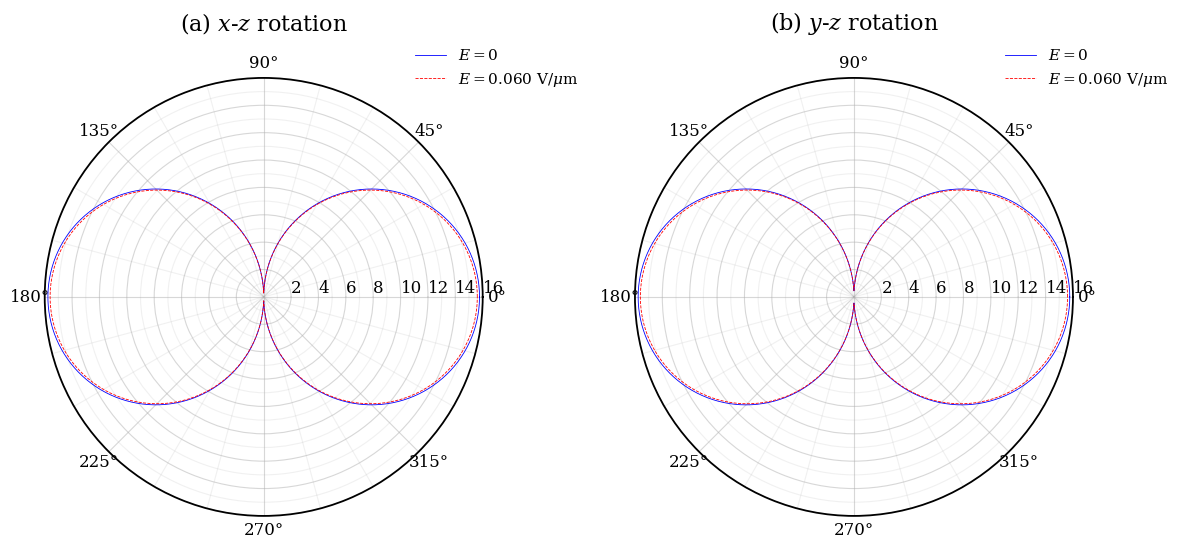

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ==================================================
# Plot settings
# ==================================================
plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 16,
    "axes.titlesize": 16,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "lines.linewidth": 2.6,
    "axes.linewidth": 1.3,
})

# ==================================================
# Load g-factor data
# ==================================================
data_xx = np.loadtxt("gfactor_xx_vs_Ey_N100_L300.dat", comments="#")
data_yy = np.loadtxt("gfactor_yy_vs_Ey_N100_L300.dat", comments="#")
data_zz = np.loadtxt("gfactor_zz_vs_Ey_N100_L300.dat", comments="#")

# --------------------------------------------------
# Row 0: zero electric field
# Row 1: finite electric field
# --------------------------------------------------
gxx_E0 = abs(data_xx[0, 7])
gyy_E0 = abs(data_yy[0, 7])
gzz_E0 = abs(data_zz[0, 7])

gxx_E1 = abs(data_xx[1, 7])
gyy_E1 = abs(data_yy[1, 7])
gzz_E1 = abs(data_zz[1, 7])

# Electric-field value from column 2 (V/um)
E1_val = data_xx[1, 2]

print("E = 0:")
print(f"gxx = {gxx_E0:.8f}, gyy = {gyy_E0:.8f}, gzz = {gzz_E0:.8f}")

print(f"\nE = {E1_val:.6f} V/um:")
print(f"gxx = {gxx_E1:.8f}, gyy = {gyy_E1:.8f}, gzz = {gzz_E1:.8f}")

# ==================================================
# Angular sweep
# theta = 0 degree means B || z
# theta = 90 degree means B || x or y
# ==================================================
theta = np.linspace(0, 2*np.pi, 721)

# x-z rotation
g_xz_E0 = np.sqrt((gxx_E0 * np.sin(theta))**2 + (gzz_E0 * np.cos(theta))**2)
g_xz_E1 = np.sqrt((gxx_E1 * np.sin(theta))**2 + (gzz_E1 * np.cos(theta))**2)

# y-z rotation
g_yz_E0 = np.sqrt((gyy_E0 * np.sin(theta))**2 + (gzz_E0 * np.cos(theta))**2)
g_yz_E1 = np.sqrt((gyy_E1 * np.sin(theta))**2 + (gzz_E1 * np.cos(theta))**2)

# ==================================================
# Colors
# ==================================================
color_E0 = "blue"
color_E1 = "red"

# ==================================================
# Two-panel polar plot
# ==================================================
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5.8),
    subplot_kw={"projection": "polar"}
)

# --------------------------------------------------
# Panel (a): x-z rotation
# --------------------------------------------------
ax = axes[0]

ax.plot(
    theta,
    g_xz_E0,
    color=color_E0,
    linestyle="-",
    label=r"$E=0$",
    lw = 0.6
)

ax.plot(
    theta,
    g_xz_E1,
    color=color_E1,
    linestyle="--",
    label=rf"$E={E1_val:.3f}$ V/$\mu$m",
    lw = 0.6
)

ax.set_title(r"(a) $x$-$z$ rotation", pad=18)

# --------------------------------------------------
# Panel (b): y-z rotation
# --------------------------------------------------
ax = axes[1]

ax.plot(
    theta,
    g_yz_E0,
    color=color_E0,
    linestyle="-",
    label=r"$E=0$",
    lw = 0.6
)

ax.plot(
    theta,
    g_yz_E1,
    color=color_E1,
    linestyle="--",
    label=rf"$E={E1_val:.3f}$ V/$\mu$m",
    lw = 0.6
)

ax.set_title(r"(b) $y$-$z$ rotation", pad=18)

# ==================================================
# Common formatting
# ==================================================
for ax in axes:

    # Major angular ticks every 45 degrees
    major_deg = np.arange(0, 360, 45)
    ax.set_xticks(np.deg2rad(major_deg))
    ax.set_xticklabels([f"{d}\N{DEGREE SIGN}" for d in major_deg])

    # Minor angular ticks every 15 degrees
    minor_deg = np.arange(0, 360, 15)
    ax.set_xticks(np.deg2rad(minor_deg), minor=True)

    ax.tick_params(axis="x", which="major", length=8, width=1.2)
    ax.tick_params(axis="x", which="minor", length=4, width=1.0)

    # Put radial labels along 0 degree direction
    ax.set_rlabel_position(0)

    # Radial ticks
    rmax = np.ceil(max(gzz_E0, gzz_E1))
    ax.set_ylim(0, rmax)

    rticks = np.arange(2, rmax + 1, 2)
    ax.set_rticks(rticks)
    ax.set_yticklabels([f"{int(r)}" for r in rticks])

    ax.yaxis.set_minor_locator(MultipleLocator(1))

    ax.grid(True, which="major", alpha=0.50)
    ax.grid(True, which="minor", alpha=0.18)

    ax.legend(
        loc="upper right",
        bbox_to_anchor=(1.25, 1.10),
        frameon=False
    )

plt.tight_layout()

plt.savefig("angular_geff_E0_Efinite_blue_red_N100_L300.pdf", dpi=300, bbox_inches="tight")
plt.savefig("angular_geff_E0_Efinite_blue_red_N100_L300.png", dpi=300, bbox_inches="tight")

plt.show()